# Explainable AI (XAI) Analysis

This notebook presents the explainability analysis of the proposed pulmonary nodule detection framework at both the **segmentation** and **classification** stages.

At the segmentation stage, decoder attention maps, Grad-CAM, and occlusion sensitivity are used to examine the spatial regions and features associated with the model's segmentation predictions.

At the classification stage, SHAP and occlusion sensitivity are applied to investigate the contribution of extracted features and image regions to the slice-level nodule-presence classification decisions.

These analyses provide complementary insights into the internal behavior of both models and help assess how their predictions are formed.

------------

### Segmentation Explainability Analysis

This cell performs an explainability analysis of the selected 2.5D DecAtt segmentation model using a representative test sample (`LIDC-IDRI-0001_slice0042_img00005`).

The analysis includes:

1. **Decoder Attention Visualization:** Extracts and visualizes the spatial, local, global, combined, and final attention maps from the decoder's third stage (`dec3`).
2. **Grad-CAM:** Generates a Grad-CAM heatmap from the decoder feature layer to highlight image regions that contribute most to the segmentation output.
3. **Occlusion Sensitivity:** Evaluates the effect of masking local image regions on the model's segmentation output.

The ground-truth mask and predicted segmentation are displayed alongside the explainability maps to facilitate visual comparison.

All visualizations are displayed directly in the notebook for the selected sample. No output files are saved.

Loading the selected segmentation model
Segmentation model loaded successfully.
Train size: 9845, Val size: 2082
Test dataloader is ready.

Locating the selected test image
Selected image: LIDC-IDRI-0001_slice0042_img00005
Patient ID: LIDC-IDRI-0001
Test sample index: 5

Running segmentation on the selected image

Computing Grad-CAM and Occlusion Sensitivity
Grad-CAM and Occlusion Sensitivity completed.


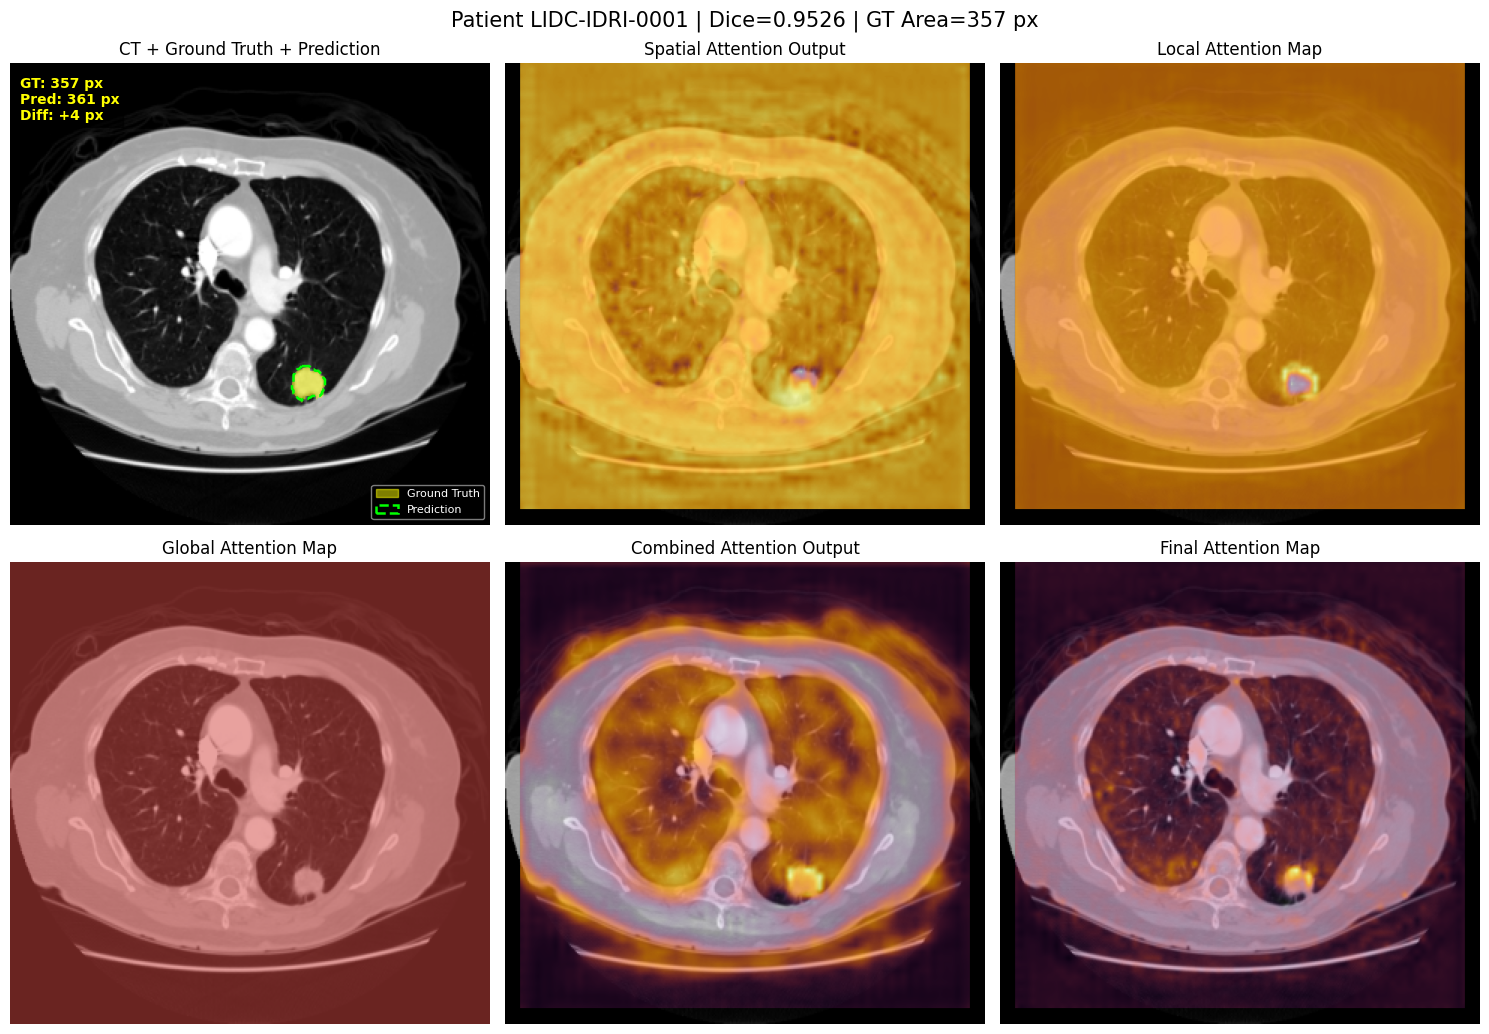

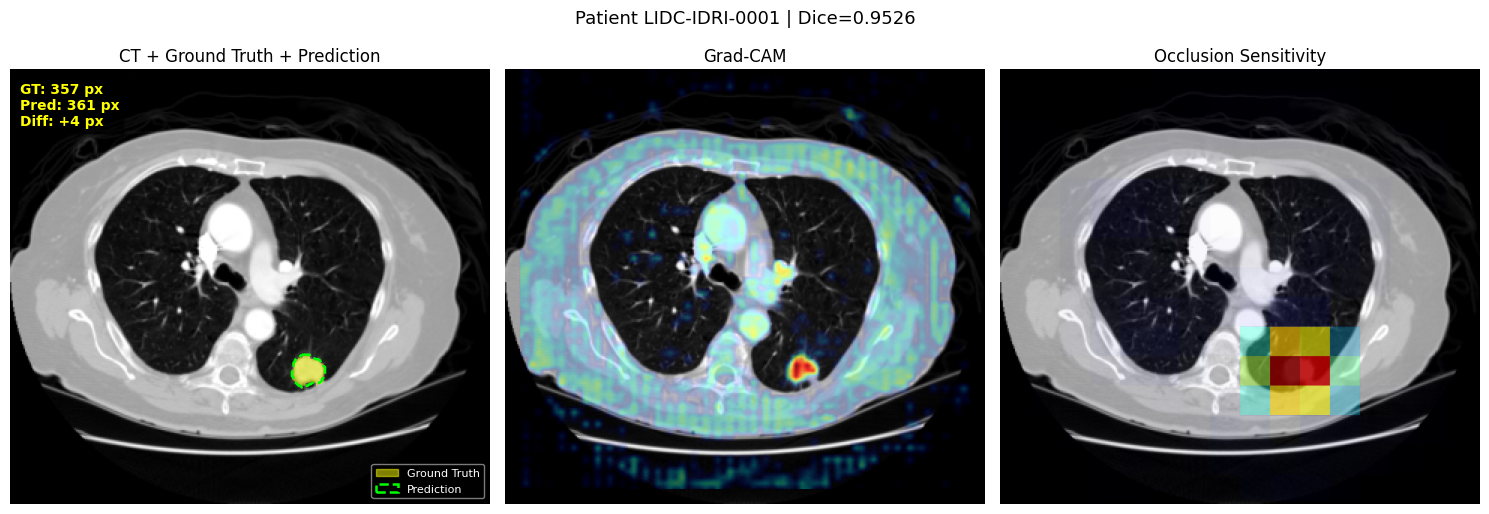


FINAL SEGMENTATION XAI RESULTS
Selected image: LIDC-IDRI-0001_slice0042_img00005
Patient ID: LIDC-IDRI-0001
Dice score: 0.9526
Ground Truth area: 357 pixels
Predicted area: 361 pixels
Pixel difference: +4 pixels

Both figures were displayed successfully.
No files were saved.


In [ ]:

# ============================================================
# Segmentation XAI for One Selected Slice
# Ground Truth + Prediction + Adaptive Attention + Grad-CAM + Occlusion
#
# Selected image:
# LIDC-IDRI-0001_slice0042_img00005
#
# The figures are displayed directly and are not saved to disk.
# ============================================================

import gc
import cv2
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_IMAGE = "LIDC-IDRI-0001_slice0042_img00005"

CKPT_PATH = "saved_models_newXAI/best_model_2.5D_DecAtt.pt"

CROP_TOP = 26

OCCLUSION_PATCH = 40
OCCLUSION_STRIDE = 20
OCCLUSION_BATCH_SIZE = 16

MAPS_TO_SHOW = [
    "spatial_mask",
    "focused",
    "local_attention",
    "global_attention",
    "combined_attention",
    "final_attention",
]

print("=" * 65)
print("Loading the selected segmentation model")
print("=" * 65)


# ============================================================
# 2. LOAD SEGMENTATION MODEL
# ============================================================

model = SwinUNetAdaptive_DS(
    in_ch=IN_CHANNELS,
    use_enc_att=False,
    use_dec_att=True
).to(device)

checkpoint = torch.load(CKPT_PATH, map_location=device)

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])

    elif "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])

    elif "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])

    else:
        model.load_state_dict(checkpoint)

else:
    model.load_state_dict(checkpoint)

model.eval()

print("Segmentation model loaded successfully.")


# ============================================================
# 3. CREATE TEST DATALOADER
# ============================================================

dl_tr, dl_va, dl_te = make_loaders_ablation(
    train_ids,
    val_ids,
    test_ids,
    use_25d=True,
    use_crop=False
)

print("Test dataloader is ready.")


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def dice_score(pred, gt):

    smooth = 1e-6

    inter = (pred * gt).sum()

    return (
        (2.0 * inter + smooth) /
        (pred.sum() + gt.sum() + smooth)
    )


def crop_top(x, n=CROP_TOP):

    return x[n:, :]


def normalize_map(x):

    x = x.astype(np.float32)
    x = x - x.min()

    if x.max() > 0:
        x = x / x.max()

    return x


# ============================================================
# 5. ATTENTION MAP POSTPROCESSING
# ============================================================

def taper_border(
    x,
    top=40,
    bottom=6,
    left=6,
    right=6,
    ref_band=15
):

    x = x.copy()
    h, w = x.shape

    if top > 0:

        band_end = min(top + ref_band, h)

        ref = np.median(
            x[top:band_end, :],
            axis=0,
            keepdims=True
        )

        for r in range(top):

            wgt = r / top

            x[r, :] = (
                (1 - wgt) * ref[0] +
                wgt * x[r, :]
            )

    if bottom > 0:

        band_start = max(h - bottom - ref_band, 0)

        ref = np.median(
            x[band_start:h - bottom, :],
            axis=0,
            keepdims=True
        )

        for r in range(bottom):

            wgt = r / bottom
            idx = h - 1 - r

            x[idx, :] = (
                (1 - wgt) * ref[0] +
                wgt * x[idx, :]
            )

    if left > 0:

        band_end = min(left + ref_band, w)

        ref = np.median(
            x[:, left:band_end],
            axis=1,
            keepdims=True
        )

        for c in range(left):

            wgt = c / left

            x[:, c] = (
                (1 - wgt) * ref[:, 0] +
                wgt * x[:, c]
            )

    if right > 0:

        band_start = max(w - right - ref_band, 0)

        ref = np.median(
            x[:, band_start:w - right],
            axis=1,
            keepdims=True
        )

        for c in range(right):

            wgt = c / right
            idx = w - 1 - c

            x[:, idx] = (
                (1 - wgt) * ref[:, 0] +
                wgt * x[:, idx]
            )

    return x


def zero_margin(x, margin=10):

    if margin <= 0:
        return x

    x = x.copy()

    x[:margin, :] = 0.0
    x[-margin:, :] = 0.0
    x[:, :margin] = 0.0
    x[:, -margin:] = 0.0

    return x


def clean_map(
    raw_map,
    top=40,
    bottom=6,
    left=6,
    right=6,
    hard_zero_margin=10
):

    x = taper_border(
        raw_map,
        top=top,
        bottom=bottom,
        left=left,
        right=right
    )

    x = normalize_map(x)

    x = zero_margin(
        x,
        margin=hard_zero_margin
    )

    x = crop_top(x)

    return x


# ============================================================
# 6. VISUALIZATION HELPERS
# ============================================================

try:

    INFERNO = matplotlib.colormaps.get_cmap("inferno")
    JET = matplotlib.colormaps.get_cmap("jet")

except AttributeError:

    INFERNO = cm.get_cmap("inferno")
    JET = cm.get_cmap("jet")


def pretty_overlay(
    ax,
    image,
    attention,
    max_alpha=0.9,
    gamma=0.55,
    cmap_name="inferno"
):

    img = normalize_map(image)

    att_range = float(
        attention.max() - attention.min()
    )

    if att_range < 1e-6:

        att = np.clip(
            attention,
            0.0,
            1.0
        ) ** gamma

    else:

        att = normalize_map(attention) ** gamma

    cmap = INFERNO if cmap_name == "inferno" else JET

    ax.imshow(
        img,
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    heat_rgba = cmap(att)

    heat_rgba[..., 3] = att * max_alpha

    ax.imshow(
        heat_rgba,
        aspect="auto"
    )


def draw_gt_filled_with_pred_contour(
    ax,
    image,
    gt,
    pred,
    title="CT + Ground Truth + Prediction"
):

    img = normalize_map(image)

    ax.imshow(
        img,
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    yellow_overlay = np.zeros(
        (*gt.shape, 4),
        dtype=np.float32
    )

    yellow_overlay[..., 0] = 1.0
    yellow_overlay[..., 1] = 1.0
    yellow_overlay[..., 2] = 0.0

    yellow_overlay[..., 3] = (
        (gt > 0.5).astype(np.float32) * 0.5
    )

    ax.imshow(
        yellow_overlay,
        aspect="auto"
    )

    ax.contour(
        pred > 0.5,
        colors="lime",
        linewidths=1.8,
        linestyles="--"
    )

    gt_patch = mpatches.Patch(
        facecolor="yellow",
        alpha=0.5,
        edgecolor="yellow",
        label="Ground Truth"
    )

    pred_patch = mpatches.Patch(
        facecolor="none",
        edgecolor="lime",
        linestyle="--",
        linewidth=1.8,
        label="Prediction"
    )

    ax.legend(
        handles=[gt_patch, pred_patch],
        loc="lower right",
        fontsize=8,
        framealpha=0.6,
        facecolor="black",
        labelcolor="white"
    )

    ax.set_title(title)


def add_size_label(ax, text):

    ax.text(
        0.02,
        0.97,
        text,
        transform=ax.transAxes,
        va="top",
        ha="left",
        color="yellow",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            facecolor="black",
            alpha=0.55,
            pad=3
        )
    )


# ============================================================
# 7. GRAD-CAM
# ============================================================

def run_gradcam(model, image, top_frac=0.05):

    model.eval()

    xb = image.unsqueeze(0).to(device)
    xb.requires_grad_(True)

    target_layer = model.up3.conv[0]

    acts = {}

    def fwd_hook(module, inp, out):
        acts["A"] = out

    hook_handle = target_layer.register_forward_hook(
        fwd_hook
    )

    output = model(xb)

    if isinstance(output, tuple):
        output = output[0]

    prob = torch.sigmoid(output)

    flat = prob.flatten()

    k = max(
        1,
        int(top_frac * flat.numel())
    )

    score = flat.topk(k).values.mean()

    A = acts["A"]

    hook_handle.remove()

    dA = torch.autograd.grad(
        score,
        A,
        retain_graph=True,
        allow_unused=True
    )[0]

    if dA is None:
        raise RuntimeError("Gradient is None.")

    A0 = A[0]
    dA0 = dA[0]

    weights = dA0.mean(
        dim=(1, 2),
        keepdim=True
    )

    cam = (weights * A0).sum(dim=0)

    cam = F.relu(cam)

    cam = (
        (cam - cam.min()) /
        (cam.max() - cam.min() + 1e-8)
    )

    return cam.detach().cpu().numpy()


# ============================================================
# 8. OCCLUSION SENSITIVITY
# ============================================================

@torch.no_grad()
def occlusion_sensitivity(
    model,
    image,
    patch=40,
    stride=20,
    batch_size=16
):

    model.eval()

    xb = image.unsqueeze(0).to(device)

    C, H, W = image.shape

    base_out = model(xb)

    if isinstance(base_out, tuple):
        base_out = base_out[0]

    base_prob = torch.sigmoid(base_out)

    base_score = base_prob.mean().item()

    ys = sorted(
        set(
            list(range(0, H - patch + 1, stride)) +
            [H - patch]
        )
    )

    xs = sorted(
        set(
            list(range(0, W - patch + 1, stride)) +
            [W - patch]
        )
    )

    heat = np.zeros(
        (H, W),
        dtype=np.float32
    )

    count = np.zeros(
        (H, W),
        dtype=np.float32
    )

    positions = [
        (y, x)
        for y in ys
        for x in xs
    ]

    for i in range(0, len(positions), batch_size):

        batch_pos = positions[
            i:i + batch_size
        ]

        batch_imgs = []

        for y, x in batch_pos:

            occ = image.clone()

            occ[
                :,
                y:y + patch,
                x:x + patch
            ] = 0.0

            batch_imgs.append(occ)

        batch_tensor = torch.stack(
            batch_imgs,
            dim=0
        ).to(device)

        out = model(batch_tensor)

        if isinstance(out, tuple):
            out = out[0]

        prob = (
            torch.sigmoid(out)
            .mean(dim=(1, 2, 3))
            .cpu()
            .numpy()
        )

        for (y, x), p in zip(batch_pos, prob):

            drop = max(
                0.0,
                base_score - float(p)
            )

            heat[
                y:y + patch,
                x:x + patch
            ] += drop

            count[
                y:y + patch,
                x:x + patch
            ] += 1.0

    count[count == 0] = 1.0

    heat = heat / count

    return heat


# ============================================================
# 9. FIND THE SELECTED IMAGE IN THE TEST SET
# ============================================================

print("\n" + "=" * 65)
print("Locating the selected test image")
print("=" * 65)

name_to_test_idx = {
    pairs[test_ids[i]][0].stem: i
    for i in range(len(test_ids))
}

if TARGET_IMAGE not in name_to_test_idx:

    raise ValueError(
        f"{TARGET_IMAGE} was not found in the test set."
    )

target_global_idx = name_to_test_idx[TARGET_IMAGE]

target_patient_id = pairs[
    test_ids[target_global_idx]
][2]

print("Selected image:", TARGET_IMAGE)
print("Patient ID:", target_patient_id)
print("Test sample index:", target_global_idx)


# ============================================================
# 10. EXTRACT THE SELECTED TEST SAMPLE
# ============================================================

print("\n" + "=" * 65)
print("Running segmentation on the selected image")
print("=" * 65)

global_idx = 0
selected_case = None

with torch.no_grad():

    for xb, yb in dl_te:

        batch_start = global_idx
        batch_end = global_idx + xb.shape[0]

        if batch_start <= target_global_idx < batch_end:

            local_idx = target_global_idx - batch_start

            xb_gpu = xb.to(device)
            yb_gpu = yb.to(device)

            _ = model(xb_gpu)

            pred = model.explain.outputs["prediction"]

            pred_bin = (pred > 0.5).float()

            gt = yb_gpu[
                local_idx, 0
            ].cpu().numpy()

            pr = pred_bin[
                local_idx, 0
            ].cpu().numpy()

            dsc = float(
                dice_score(pr, gt)
            )

            area = float(gt.sum())

            img_full = xb_gpu[
                local_idx
            ].cpu().numpy()

            if img_full.ndim == 3:
                img_full = img_full[1]

            img_display = crop_top(img_full)
            gt_display = crop_top(gt)
            pred_display = crop_top(pr)

            selected_case = {
                "image": img_display,
                "image_full": img_full,
                "gt": gt_display,
                "pred": pred_display,
                "dice": dsc,
                "area": area,
                "pid": target_patient_id,
                "image_tensor": xb[local_idx].clone(),
                "pred_full": pr,
                "gt_full": gt
            }

            # Extract decoder attention maps
            att = model.explain.attention["dec3"]

            selected_case["dec3"] = {}

            for key in MAPS_TO_SHOW:

                if key not in att:
                    continue

                value = att[key]

                if not torch.is_tensor(value):
                    continue

                x = value[
                    local_idx:local_idx + 1
                ]

                if x.shape[1] > 1:
                    x = x.mean(
                        1,
                        keepdim=True
                    )

                if key == "global_attention":

                    flat_val = float(
                        x.mean().item()
                    )

                    selected_case["dec3"][key] = np.full(
                        img_display.shape,
                        flat_val,
                        dtype=np.float32
                    )

                    continue

                x = F.interpolate(
                    x,
                    size=img_full.shape,
                    mode="bilinear",
                    align_corners=False
                )

                x = (
                    x[0, 0]
                    .detach()
                    .cpu()
                    .numpy()
                )

                selected_case["dec3"][key] = clean_map(x)

            break

        global_idx = batch_end


if selected_case is None:

    raise RuntimeError(
        "The selected image was not retrieved from the test dataloader. "
        "Check the test dataloader ordering and test_ids."
    )


# ============================================================
# 11. COMPUTE GRAD-CAM AND OCCLUSION
# ============================================================

print("\n" + "=" * 65)
print("Computing Grad-CAM and Occlusion Sensitivity")
print("=" * 65)

cam_raw = run_gradcam(
    model,
    selected_case["image_tensor"]
)

H_full, W_full = selected_case["image_full"].shape

cam_raw = cv2.resize(
    cam_raw,
    (W_full, H_full),
    interpolation=cv2.INTER_LINEAR
)

selected_case["gradcam"] = clean_map(cam_raw)


occ_raw = occlusion_sensitivity(
    model,
    selected_case["image_tensor"],
    patch=OCCLUSION_PATCH,
    stride=OCCLUSION_STRIDE,
    batch_size=OCCLUSION_BATCH_SIZE
)

selected_case["occlusion"] = clean_map(
    occ_raw,
    top=4,
    bottom=4,
    left=4,
    right=4,
    hard_zero_margin=2
)

print("Grad-CAM and Occlusion Sensitivity completed.")


# ============================================================
# 12. DISPLAY ATTENTION MAPS
# ============================================================

case = selected_case

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10.5)
)

fig.suptitle(
    f"Patient {case['pid']} | "
    f"Dice={case['dice']:.4f} | "
    f"GT Area={case['area']:.0f} px",
    fontsize=15
)

# Panel 1: Ground Truth and Prediction

draw_gt_filled_with_pred_contour(
    axes[0, 0],
    case["image"],
    case["gt"],
    case["pred"]
)

gt_size = int(case["gt"].sum())
pred_size = int(case["pred"].sum())

diff = pred_size - gt_size

add_size_label(
    axes[0, 0],
    f"GT: {gt_size} px\n"
    f"Pred: {pred_size} px\n"
    f"Diff: {diff:+d} px"
)

# Panel 2: Spatial Attention

pretty_overlay(
    axes[0, 1],
    case["image"],
    case["dec3"]["focused"]
)

axes[0, 1].set_title("Spatial Attention Output")

# Panel 3: Local Attention

pretty_overlay(
    axes[0, 2],
    case["image"],
    case["dec3"]["local_attention"]
)

axes[0, 2].set_title("Local Attention Map")

# Panel 4: Global Attention

pretty_overlay(
    axes[1, 0],
    case["image"],
    case["dec3"]["global_attention"]
)

axes[1, 0].set_title("Global Attention Map")

# Panel 5: Combined Attention

pretty_overlay(
    axes[1, 1],
    case["image"],
    case["dec3"]["combined_attention"]
)

axes[1, 1].set_title("Combined Attention Output")

# Panel 6: Final Attention

pretty_overlay(
    axes[1, 2],
    case["image"],
    case["dec3"]["final_attention"]
)

axes[1, 2].set_title("Final Attention Map")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 13. DISPLAY GRAD-CAM AND OCCLUSION
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5.2)
)

fig.suptitle(
    f"Patient {case['pid']} | "
    f"Dice={case['dice']:.4f}",
    fontsize=13
)

# Panel 1: Ground Truth and Prediction

draw_gt_filled_with_pred_contour(
    axes[0],
    case["image"],
    case["gt"],
    case["pred"],
    title="CT + Ground Truth + Prediction"
)

add_size_label(
    axes[0],
    f"GT: {gt_size} px\n"
    f"Pred: {pred_size} px\n"
    f"Diff: {diff:+d} px"
)

# Panel 2: Grad-CAM

pretty_overlay(
    axes[1],
    case["image"],
    case["gradcam"],
    cmap_name="jet"
)

axes[1].set_title("Grad-CAM")

# Panel 3: Occlusion Sensitivity

pretty_overlay(
    axes[2],
    case["image"],
    case["occlusion"],
    cmap_name="jet"
)

axes[2].set_title("Occlusion Sensitivity")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 14. FINAL REPORT
# ============================================================

print("\n" + "=" * 65)
print("FINAL SEGMENTATION XAI RESULTS")
print("=" * 65)

print("Selected image:", TARGET_IMAGE)
print("Patient ID:", case["pid"])
print(f"Dice score: {case['dice']:.4f}")
print(f"Ground Truth area: {gt_size} pixels")
print(f"Predicted area: {pred_size} pixels")
print(f"Pixel difference: {diff:+d} pixels")

print("\nBoth figures were displayed successfully.")
print("No files were saved.")

print("=" * 65)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


-------------------

### Quantitative Attention Alignment Analysis

This cell quantitatively evaluates how well the decoder attention maps align with the ground-truth nodule regions across the test set. Five attention maps are assessed: spatial, local, global, combined, and final attention.

Three metrics are calculated: **AUC**, which measures how effectively each attention map assigns higher values to nodule regions; **enrichment**, which compares the attention assigned to the ground-truth region with the average attention across the image; and **Hit Rate**, which measures whether the highest-attention location falls within the ground-truth nodule region. The analysis includes all eligible test slices and a separate subset with Dice scores of at least 0.5. Patient-level bootstrap confidence intervals are also calculated for the relevant metrics.

The cell generates the quantitative results and the corresponding enrichment comparison plot. These results are reported in **Figure 16 and Table 21**.

Training samples: 9,845
Validation samples: 2,082
Test samples: 2,016
Model loaded | Test slices: 2016 | Patients: 79
Evaluated 320/2016 test slices
Evaluated 640/2016 test slices
Evaluated 960/2016 test slices
Evaluated 1280/2016 test slices
Evaluated 1600/2016 test slices
Evaluated 1920/2016 test slices

Eligible slices: 2016 | Mean Dice: 0.6426

ATTENTION MAP ALIGNMENT RESULTS
Attention map  AUC (All)  Enrichment (All)  Hit rate (All)  AUC (Dice >= 0.5)  Enrichment (Dice >= 0.5)  Hit rate (Dice >= 0.5)
      Spatial      0.841             2.814           0.732              0.888                     3.050                   0.882
        Local      0.875             1.676           0.802              0.889                     1.640                   0.972
       Global      0.500             1.000           0.002              0.500                     1.000                   0.001
     Combined      0.890             2.816           0.785              0.932                     3.002  

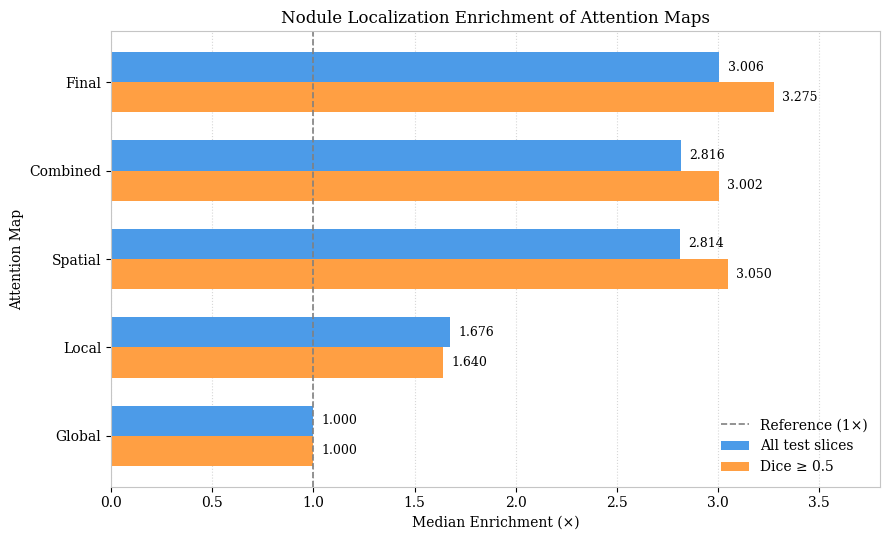


Results saved to: XAI_Attention_Quantitative_v1


In [ ]:
import os
import gc
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from scipy.stats import rankdata
from scipy.ndimage import binary_fill_holes, binary_dilation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_PATH = r"Checkpoints\best_model_2.5D_DecAtt.pt"
OUT_DIR = "XAI_Attention_Quantitative_v1"

SEED = 41
MIN_GT_AREA = 1
DILATIONS_PX = [0, 5, 10]
PRIMARY_DILATION = 5
N_BOOT = 2000

os.makedirs(OUT_DIR, exist_ok=True)


def taper_border(x, top=40, bottom=6, left=6, right=6, ref_band=15):
    x = x.copy()
    h, w = x.shape

    if top > 0:
        ref = np.median(x[top:min(top + ref_band, h), :], axis=0, keepdims=True)
        for r in range(top):
            x[r, :] = (1 - r / top) * ref[0] + (r / top) * x[r, :]

    if bottom > 0:
        ref = np.median(
            x[max(h - bottom - ref_band, 0):h - bottom, :],
            axis=0,
            keepdims=True
        )
        for r in range(bottom):
            x[h - 1 - r, :] = (
                (1 - r / bottom) * ref[0]
                + (r / bottom) * x[h - 1 - r, :]
            )

    if left > 0:
        ref = np.median(x[:, left:min(left + ref_band, w)], axis=1, keepdims=True)
        for c in range(left):
            x[:, c] = (1 - c / left) * ref[:, 0] + (c / left) * x[:, c]

    if right > 0:
        ref = np.median(
            x[:, max(w - right - ref_band, 0):w - right],
            axis=1,
            keepdims=True
        )
        for c in range(right):
            x[:, w - 1 - c] = (
                (1 - c / right) * ref[:, 0]
                + (c / right) * x[:, w - 1 - c]
            )

    return x


def normalize_map(x):
    x = x.astype(np.float32)
    x = x - x.min()
    return x / x.max() if x.max() > 0 else x


def zero_margin(x, margin=10):
    x = x.copy()
    if margin > 0:
        x[:margin, :] = 0.0
        x[-margin:, :] = 0.0
        x[:, :margin] = 0.0
        x[:, -margin:] = 0.0
    return x


def get_body_mask(img, threshold=0.05):
    return binary_dilation(
        binary_fill_holes(img > threshold),
        iterations=4
    )


def dilate_mask(gt_bool, px):
    if px <= 0:
        return gt_bool.copy()

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (2 * px + 1, 2 * px + 1)
    )

    return cv2.dilate(
        gt_bool.astype(np.uint8),
        kernel
    ).astype(bool)


def peak_location(heat):
    maximum = float(heat.max())
    ys, xs = np.nonzero(
        heat >= maximum - 1e-6 * max(abs(maximum), 1e-12)
    )
    return int(round(ys.mean())), int(round(xs.mean()))


def map_metrics(heat, gt_bool, body, dilations):
    heat = np.clip(heat, 0, None).astype(np.float64)

    total = heat.sum()
    heat_body = heat * body
    total_body = heat_body.sum()

    is_constant = float(np.ptp(heat)) == 0.0

    py, px = (
        peak_location(heat)
        if total > 0 and not is_constant
        else (None, None)
    )

    ranks_body = rankdata(heat[body]) if body.any() else None

    results = {}

    for dilation in dilations:
        region = dilate_mask(gt_bool, dilation)

        area_frac = float(region.mean())
        area_frac_body = float(
            (region & body).sum() / max(body.sum(), 1)
        )

        inside_frac = (
            float(heat[region].sum() / total)
            if total > 0 else np.nan
        )

        inside_frac_body = (
            float(heat_body[region].sum() / total_body)
            if total_body > 0 else np.nan
        )

        positive = region[body] if ranks_body is not None else None

        if positive is not None and 0 < positive.sum() < positive.size:
            n_positive = positive.sum()
            n_negative = positive.size - n_positive

            auc = float(
                (
                    ranks_body[positive].sum()
                    - n_positive * (n_positive + 1) / 2
                ) / (n_positive * n_negative)
            )
        else:
            auc = np.nan

        hit = (
            float(region[py, px])
            if py is not None else np.nan
        )

        results[dilation] = {
            "inside_frac": inside_frac,
            "area_frac": area_frac,
            "enrichment": (
                inside_frac / area_frac
                if area_frac > 0 else np.nan
            ),
            "inside_frac_body": inside_frac_body,
            "area_frac_body": area_frac_body,
            "enrichment_body": (
                inside_frac_body / area_frac_body
                if area_frac_body > 0 else np.nan
            ),
            "auc_body": auc,
            "hit": hit
        }

    return results


def patient_bootstrap(df, column, n_boot=N_BOOT, seed=0):
    data = df.dropna(subset=[column])

    if data.empty:
        return np.nan, np.nan, np.nan

    grouped = data.groupby("pid")[column].agg(["sum", "count"])

    sums = grouped["sum"].to_numpy(dtype=float)
    counts = grouped["count"].to_numpy(dtype=float)

    point = sums.sum() / counts.sum()

    rng = np.random.default_rng(seed)
    indices = rng.integers(
        0,
        len(sums),
        size=(n_boot, len(sums))
    )

    bootstrap_values = (
        sums[indices].sum(axis=1)
        / counts[indices].sum(axis=1)
    )

    lower, upper = np.percentile(bootstrap_values, [2.5, 97.5])

    return point, float(lower), float(upper)


def dice_np(pred, gt, eps=1e-6):
    return (
        2.0 * float((pred * gt).sum())
        / (float(pred.sum()) + float(gt.sum()) + eps)
    )


def forward_logits(model, x):
    output = model(x)
    return output[0] if isinstance(output, (tuple, list)) else output


def att_maps_batch(model, size):
    attention = model.explain.attention
    dec3 = attention["dec3"]

    global_map = dec3.get("global_attention")

    if global_map is None:
        global_map = model.dec_att3.cache.get("global_attention")

    if global_map is None:
        raise KeyError(
            "Global attention was not found in the dec3 attention cache."
        )

    raw_maps = {
        "spatial_mask": attention["dec3_mask"],
        "local_attention": dec3["local_attention"].mean(1, keepdim=True),
        "global_attention": global_map.mean(1, keepdim=True),
        "combined_attention": dec3["combined_attention"].mean(1, keepdim=True),
        "final_attention": dec3["final_attention"].mean(1, keepdim=True)
    }

    return {
        name: F.interpolate(
            value.float(),
            size=size,
            mode="bilinear",
            align_corners=False
        )[:, 0].cpu().numpy()
        for name, value in raw_maps.items()
    }


if "SwinUNetAdaptive_DS" not in globals():
    raise RuntimeError("SwinUNetAdaptive_DS is not defined.")

model = SwinUNetAdaptive_DS(
    in_ch=IN_CHANNELS,
    use_enc_att=False,
    use_dec_att=True
).to(device)

checkpoint = torch.load(CKPT_PATH, map_location=device)

if isinstance(checkpoint, dict):
    for key in ["model_state_dict", "state_dict", "model_state"]:
        if key in checkpoint:
            checkpoint = checkpoint[key]
            break

model.load_state_dict(checkpoint)
model.eval()

_, _, dl_te = make_loaders_ablation(
    train_ids,
    val_ids,
    test_ids,
    use_25d=True,
    use_crop=False
)

n_total = len(dl_te.dataset)

assert n_total == len(test_ids), (
    "The test loader order must match test_ids."
)

pid_of = np.array([
    pairs[test_ids[i]][2]
    for i in range(n_total)
])

print(
    f"Model loaded | Test slices: {n_total} | "
    f"Patients: {len(set(pid_of))}"
)

dice_base = np.full(n_total, np.nan)
rows = []
global_idx = 0

with torch.no_grad():
    for xb, yb in dl_te:
        xb_gpu = xb.to(device)

        logits = forward_logits(model, xb_gpu)

        predictions = (
            (torch.sigmoid(logits) > 0.5)
            .float()
            .cpu()
            .numpy()[:, 0]
        )

        gt_batch = yb[:, 0].numpy() > 0.5

        maps = att_maps_batch(model, xb.shape[-2:])

        for i in range(xb.size(0)):
            if gt_batch[i].sum() >= MIN_GT_AREA:

                dice_base[global_idx] = dice_np(
                    predictions[i],
                    gt_batch[i].astype(np.float32)
                )

                body = get_body_mask(xb[i, 1].numpy())

                for name, attention_map in maps.items():

                    raw_map = normalize_map(attention_map[i])

                    cleaned_map = zero_margin(
                        normalize_map(taper_border(attention_map[i])),
                        margin=10
                    )

                    for variant, heat in [
                        ("raw", raw_map),
                        ("cleaned", cleaned_map)
                    ]:

                        metrics = map_metrics(
                            heat,
                            gt_batch[i],
                            body,
                            DILATIONS_PX
                        )

                        for dilation, values in metrics.items():
                            rows.append({
                                "gidx": global_idx,
                                "pid": pid_of[global_idx],
                                "dice": dice_base[global_idx],
                                "map": name,
                                "variant": variant,
                                "dilation": dilation,
                                **values
                            })

            global_idx += 1

        if global_idx % 320 < xb.size(0):
            print(f"Evaluated {global_idx}/{n_total} test slices")

loc = pd.DataFrame(rows)

loc.to_csv(
    os.path.join(OUT_DIR, "per_slice_attention_alignment.csv"),
    index=False
)

eligible = ~np.isnan(dice_base)

print(
    f"\nEligible slices: {int(eligible.sum())} | "
    f"Mean Dice: {np.nanmean(dice_base):.4f}"
)

summary_rows = []

for name in loc["map"].unique():

    selected_variant = "raw" if name == "global_attention" else "cleaned"

    for group_name, group_data in [
        ("All test slices", loc[loc["dice"].notna()]),
        ("Dice >= 0.5", loc[loc["dice"] >= 0.5])
    ]:

        subset = group_data[
            (group_data["map"] == name)
            & (group_data["variant"] == selected_variant)
            & (group_data["dilation"] == PRIMARY_DILATION)
        ].copy()

        if subset.empty:
            continue

        auc, auc_lo, auc_hi = patient_bootstrap(
            subset, "auc_body", seed=SEED
        )

        hit, hit_lo, hit_hi = patient_bootstrap(
            subset, "hit", seed=SEED + 1
        )

        summary_rows.append({
            "Attention map": name,
            "Group": group_name,
            "n_slices": len(subset),
            "n_patients": subset["pid"].nunique(),
            "AUC": auc,
            "AUC 95% CI": f"{auc_lo:.3f}–{auc_hi:.3f}",
            "Enrichment": subset["enrichment"].median(),
            "Hit rate": hit,
            "Hit rate 95% CI": (
                f"{hit_lo:.3f}–{hit_hi:.3f}"
                if np.isfinite(hit) else "Undefined"
            )
        })

summary = pd.DataFrame(summary_rows)

summary.to_csv(
    os.path.join(OUT_DIR, "attention_alignment_summary.csv"),
    index=False
)

map_order = [
    "spatial_mask",
    "local_attention",
    "global_attention",
    "combined_attention",
    "final_attention"
]

display_names = {
    "spatial_mask": "Spatial",
    "local_attention": "Local",
    "global_attention": "Global",
    "combined_attention": "Combined",
    "final_attention": "Final"
}

table_rows = []

for name in map_order:
    row = {"Attention map": display_names[name]}

    for group_name, suffix in [
        ("All test slices", "All"),
        ("Dice >= 0.5", "Dice >= 0.5")
    ]:
        result = summary[
            (summary["Attention map"] == name)
            & (summary["Group"] == group_name)
        ]

        if result.empty:
            continue

        result = result.iloc[0]

        row[f"AUC ({suffix})"] = (
            result["AUC"] if np.isfinite(result["AUC"]) else np.nan
        )
        row[f"Enrichment ({suffix})"] = result["Enrichment"]
        row[f"Hit rate ({suffix})"] = (
            result["Hit rate"]
            if np.isfinite(result["Hit rate"])
            else "Undefined"
        )

    table_rows.append(row)

final_table = pd.DataFrame(table_rows)

print("\n" + "=" * 100)
print("ATTENTION MAP ALIGNMENT RESULTS")
print("=" * 100)
print(final_table.round(3).to_string(index=False))

final_table.to_csv(
    os.path.join(OUT_DIR, "attention_alignment_final_table.csv"),
    index=False
)

plot_data = summary[
    summary["Group"].isin(["All test slices", "Dice >= 0.5"])
].copy()

enrichment_all = []
enrichment_dice = []

for name in map_order:
    all_value = plot_data[
        (plot_data["Attention map"] == name)
        & (plot_data["Group"] == "All test slices")
    ]["Enrichment"].iloc[0]

    dice_value = plot_data[
        (plot_data["Attention map"] == name)
        & (plot_data["Group"] == "Dice >= 0.5")
    ]["Enrichment"].iloc[0]

    enrichment_all.append(all_value)
    enrichment_dice.append(dice_value)

maps = [display_names[name] for name in map_order]

enrichment_all = np.array(enrichment_all, dtype=float)
enrichment_dice = np.array(enrichment_dice, dtype=float)

order = np.argsort(enrichment_all)[::-1]

maps = [maps[i] for i in order]
enrichment_all = enrichment_all[order]
enrichment_dice = enrichment_dice[order]

y = np.arange(len(maps))
height = 0.34

fig, ax = plt.subplots(figsize=(9, 5.5))

color_all = "#4C9BE8"
color_dice = "#FF9F43"

ax.barh(
    y - height / 2,
    enrichment_all,
    height,
    color=color_all,
    label="All test slices"
)

ax.barh(
    y + height / 2,
    enrichment_dice,
    height,
    color=color_dice,
    label="Dice ≥ 0.5"
)

ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1.2,
    color="gray",
    label="Reference (1×)"
)

for i, (v1, v2) in enumerate(zip(enrichment_all, enrichment_dice)):
    ax.text(
        v1 + 0.04,
        i - height / 2,
        f"{v1:.3f}",
        va="center",
        fontsize=9
    )

    ax.text(
        v2 + 0.04,
        i + height / 2,
        f"{v2:.3f}",
        va="center",
        fontsize=9
    )

ax.set_yticks(y)
ax.set_yticklabels(maps)
ax.invert_yaxis()

ax.set_xlabel("Median Enrichment (×)")
ax.set_ylabel("Attention Map")
ax.set_title("Nodule Localization Enrichment of Attention Maps")

ax.set_xlim(0, 3.8)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_edgecolor("#c5c5c5")
    spine.set_linewidth(0.8)

ax.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "attention_enrichment_comparison.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(OUT_DIR, "attention_enrichment_comparison.pdf"),
    bbox_inches="tight"
)

plt.show()

print(f"\nResults saved to: {OUT_DIR}")

--------------

### Classification Explainability Analysis

This section presents the explainability analysis of the XGBoost classifier used for slice-level nodule-presence classification. SHAP and occlusion sensitivity are used to examine the contribution of input features and image regions to the classification predictions. SHAP provides feature-level explanations, while occlusion sensitivity evaluates how masking different image regions affects the predicted probability. These analyses provide complementary insights into the classifier's decision-making process.

#### SHAP and Occlusion Sensitivity Visualization

This cell presents the explainability results for the selected test slice, `LIDC-IDRI-0001_slice0042_img00005`. SHAP identifies the ten features with the largest absolute contributions to the classification prediction, with positive and negative SHAP values indicating contributions toward and against nodule presence, respectively. Occlusion sensitivity evaluates the importance of different image regions by masking fixed-size patches and measuring the resulting changes in the predicted nodule probability. The figure combines the CT image with its ground-truth and predicted masks, the SHAP feature importance plot, and the occlusion sensitivity map.

Segmentation model loaded.
XGBoost model and SHAP explainer loaded.
Selected image: LIDC-IDRI-0001_slice0042_img00005
GT mask area: 357
Predicted mask area: 361
Pixel count verified: 361
Classification probability: 0.9815
Calculating occlusion sensitivity...


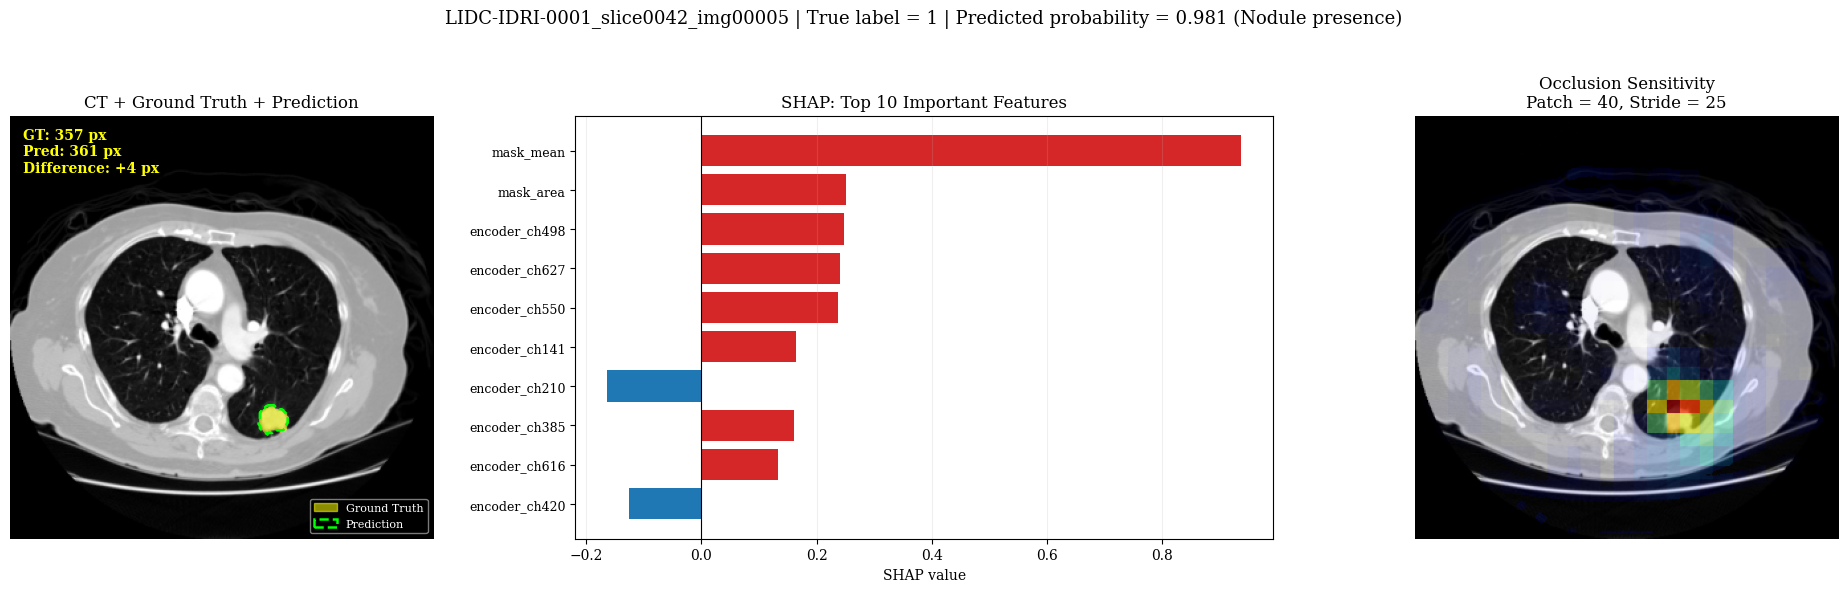


========== FINAL RESULTS ==========
Image: LIDC-IDRI-0001_slice0042_img00005
GT size: 357 pixels
Predicted size: 361 pixels
Pixel difference: 4
Classification probability: 0.9815
Occlusion baseline probability: 0.9815
Most important SHAP feature: mask_mean
Saved figure: Classification/XAI_Results_SHAP\LIDC-IDRI-0001_slice0042_img00005_SHAP_Occlusion.png


In [ ]:

# ============================================================
# Classification XAI for one selected slice
# CT + Ground Truth + Prediction + SHAP + Occlusion Sensitivity
# ============================================================

import os
import cv2
import torch
import joblib
import numpy as np
import pandas as pd
import torch.nn.functional as F

import shap
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from scipy.ndimage import binary_fill_holes, binary_dilation

# ============================================================
# 1. CONFIG
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_IMAGE = "LIDC-IDRI-0001_slice0042_img00005"

SAVE_DIR = "Classification/XAI_Results_SHAP"
os.makedirs(SAVE_DIR, exist_ok=True)

SEG_CKPT_PATH = r"Checkpoints\best_model_2.5D_DecAtt.pt"

ALIGNED_CSV = r"Classification\Final_Feature_MergedPosNeg_2.5D_DecAtt_S41_ALIGNED_FULL_FIXED.csv"

XGB_BUNDLE_PATH = r"Classification\saved_xgb_models_FINAL_v2\xgb_seed65.joblib"

IMG_POS_DIR = r"data\DatasetResized320png\resized_images320"
GT_MASK_DIR = r"data\DatasetResized320png\resized_masks320"

IMG_SIZE = 320
TOP_K_SHAP_DISPLAY = 10
OCCLUSION_PATCH = 40
OCCLUSION_STRIDE = 25

HAND_FEATURES = [
    "img_mean", "img_std", "img_max", "mask_mean",
    "mask_area", "mask_ratio", "masked_mean", "masked_std"
]

# ============================================================
# 2. CHECK REQUIRED SEGMENTATION DEFINITIONS
# ============================================================

required = ["SwinUNetAdaptive_DS", "pairs", "stack_25d"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        "Run the original segmentation setup cells first. "
        f"Missing definitions: {missing}"
    )

for path in [SEG_CKPT_PATH, ALIGNED_CSV, XGB_BUNDLE_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

# ============================================================
# 3. LOAD SEGMENTATION MODEL
# ============================================================

seg_model = SwinUNetAdaptive_DS(
    in_ch=3,
    use_enc_att=False,
    use_dec_att=True
).to(device)

ckpt = torch.load(SEG_CKPT_PATH, map_location=device)

if isinstance(ckpt, dict):
    loaded = False

    for key in ["model_state_dict", "state_dict", "model_state"]:
        if key in ckpt:
            seg_model.load_state_dict(ckpt[key])
            loaded = True
            break

    if not loaded:
        seg_model.load_state_dict(ckpt)
else:
    seg_model.load_state_dict(ckpt)

seg_model.eval()

for p in seg_model.parameters():
    p.requires_grad_(False)

print("Segmentation model loaded.")

# ============================================================
# 4. LOAD XGBOOST AND SHAP
# ============================================================

bundle = joblib.load(XGB_BUNDLE_PATH)

clf = bundle["model"]
scaler = bundle["scaler"]
feature_cols_all = list(bundle["feature_cols"])

explainer = shap.TreeExplainer(clf)

if len(feature_cols_all) != 776:
    raise ValueError(
        f"Expected 776 features, found {len(feature_cols_all)}."
    )

print("XGBoost model and SHAP explainer loaded.")

# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def norm_name(x):
    return str(x).replace(".png", "").strip()


def load_gray(path):

    if pd.isna(path) or not os.path.exists(str(path)):
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)

    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)

    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    return img.astype(np.float32) / 255.0


name_to_pairs_idx = {
    p[0].stem: i for i, p in enumerate(pairs)
}


def build_25d_tensor_aligned(image_name):

    if image_name not in name_to_pairs_idx:
        raise KeyError(
            f"{image_name} was not found in segmentation pairs."
        )

    idx = name_to_pairs_idx[image_name]

    arr = stack_25d(idx, k=3)

    return torch.from_numpy(arr).float()


# ============================================================
# 6. PREDICT MASK
# ============================================================

@torch.no_grad()
def get_predicted_mask(img_tensor):

    xb = img_tensor.unsqueeze(0).to(device)

    out = seg_model(xb)

    if isinstance(out, (tuple, list)):
        out = out[0]

    # Preserve the threshold used in the 361-pixel diagnostic.
    pred_mask = (out.float() > 0.5).float()[0, 0].cpu().numpy()

    return pred_mask


# ============================================================
# 7. ENCODER FEATURE EXTRACTION
# ============================================================

@torch.no_grad()
def get_encoder_feat_map(img_tensor):

    captured = {}

    def hook_fn(module, inp, out):
        captured["features"] = (
            out[-1] if isinstance(out, (tuple, list)) else out
        ).detach()

    hook = seg_model.encoder.register_forward_hook(hook_fn)

    x = img_tensor.unsqueeze(0).to(device)

    x = F.interpolate(
        x,
        (seg_model.patch_size, seg_model.patch_size),
        mode="bilinear",
        align_corners=False
    )

    _ = seg_model.encoder(x)

    hook.remove()

    features = captured["features"]

    if features.dim() == 4 and features.shape[-1] > features.shape[1]:
        features = features.permute(0, 3, 1, 2).contiguous()

    return features


def pooled_768(feat_map):

    return (
        F.adaptive_avg_pool2d(feat_map, (1, 1))
        .view(-1)
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )


def full_feature_vector(image, mask, encoder_768):

    mask_binary = mask > 0.5
    masked = image * mask_binary

    handcrafted = np.array(
        [
            image.mean(),
            image.std(),
            image.max(),
            mask.mean(),
            mask.sum(),
            mask_binary.mean(),
            masked.mean(),
            masked.std()
        ],
        dtype=np.float32
    )

    return np.concatenate([
        encoder_768.astype(np.float32),
        handcrafted
    ])


def predict_prob(full_vec):

    scaled = scaler.transform(full_vec.reshape(1, -1))

    return float(clf.predict_proba(scaled)[0, 1])


# ============================================================
# 8. SHAP
# ============================================================

def shap_stage1(full_vec):

    scaled = scaler.transform(full_vec.reshape(1, -1))

    shap_vals = explainer.shap_values(scaled)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[-1]

    return np.asarray(shap_vals).reshape(-1)


def feature_name(index):

    if index < 768:
        return f"encoder_ch{index}"

    return HAND_FEATURES[index - 768]


# ============================================================
# 9. OCCLUSION SENSITIVITY
# ============================================================

@torch.no_grad()
def occlusion_classification(
    img_25d,
    mask_2d,
    patch=40,
    stride=25
):

    H, W = img_25d.shape[-2:]

    base_fmap = get_encoder_feat_map(img_25d)
    base_768 = pooled_768(base_fmap)

    base_vec = full_feature_vector(
        img_25d[1].cpu().numpy(),
        mask_2d,
        base_768
    )

    base_prob = predict_prob(base_vec)

    ys = sorted(
        set(list(range(0, H - patch + 1, stride)) + [H - patch])
    )

    xs = sorted(
        set(list(range(0, W - patch + 1, stride)) + [W - patch])
    )

    heat = np.zeros((H, W), dtype=np.float32)
    count = np.zeros((H, W), dtype=np.float32)

    for y in ys:
        for x in xs:

            occ = img_25d.clone()
            occ[:, y:y + patch, x:x + patch] = 0.0

            fmap = get_encoder_feat_map(occ)
            pooled = pooled_768(fmap)

            # Recalculate image statistics after occlusion.
            occ_image = occ[1].cpu().numpy()

            vec = full_feature_vector(
                occ_image,
                mask_2d,
                pooled
            )

            prob = predict_prob(vec)

            # Positive values indicate a reduction in
            # nodule-presence probability after occlusion.
            drop = max(0.0, base_prob - prob)

            heat[y:y + patch, x:x + patch] += drop
            count[y:y + patch, x:x + patch] += 1.0

    count[count == 0] = 1.0

    return heat / count, base_prob


# ============================================================
# 10. VISUALIZATION HELPERS
# ============================================================

def normalize_map(x):

    x = x.astype(np.float32)
    x = x - x.min()

    if x.max() > 0:
        x = x / x.max()

    return x


def taper_border(
    x,
    top=40,
    bottom=6,
    left=6,
    right=6,
    ref_band=15
):

    x = x.copy()
    h, w = x.shape

    if top > 0:
        band_end = min(top + ref_band, h)
        ref = np.median(x[top:band_end, :], axis=0)

        for r in range(top):
            weight = r / top
            x[r, :] = (1 - weight) * ref + weight * x[r, :]

    if bottom > 0:
        band_start = max(h - bottom - ref_band, 0)
        ref = np.median(x[band_start:h - bottom, :], axis=0)

        for r in range(bottom):
            weight = r / bottom
            idx = h - 1 - r
            x[idx, :] = (1 - weight) * ref + weight * x[idx, :]

    if left > 0:
        band_end = min(left + ref_band, w)
        ref = np.median(x[:, left:band_end], axis=1)

        for c in range(left):
            weight = c / left
            x[:, c] = (1 - weight) * ref + weight * x[:, c]

    if right > 0:
        band_start = max(w - right - ref_band, 0)
        ref = np.median(x[:, band_start:w - right], axis=1)

        for c in range(right):
            weight = c / right
            idx = w - 1 - c
            x[:, idx] = (1 - weight) * ref + weight * x[:, idx]

    return x


def zero_margin(x, margin=10):

    if margin <= 0:
        return x

    x = x.copy()
    x[:margin, :] = 0.0
    x[-margin:, :] = 0.0
    x[:, :margin] = 0.0
    x[:, -margin:] = 0.0

    return x


def clean_map(raw_map, hard_zero_margin=4):

    x = taper_border(raw_map)
    x = normalize_map(x)

    return zero_margin(x, margin=hard_zero_margin)


try:
    JET = matplotlib.colormaps.get_cmap("jet")
except AttributeError:
    JET = cm.get_cmap("jet")


def pretty_overlay(ax, image, attention, max_alpha=0.85, gamma=0.6):

    img = normalize_map(image)
    att = normalize_map(attention) ** gamma

    ax.imshow(img, cmap="gray", vmin=0, vmax=1)

    heat_rgba = JET(att)
    heat_rgba[..., 3] = att * max_alpha

    ax.imshow(heat_rgba)


def draw_gt_pred_combined(ax, image, gt_mask, pred_mask):

    import matplotlib.patches as mpatches

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)

    yellow_overlay = np.zeros(
        (*gt_mask.shape, 4), dtype=np.float32
    )

    yellow_overlay[..., 0] = 1.0
    yellow_overlay[..., 1] = 1.0
    yellow_overlay[..., 2] = 0.0
    yellow_overlay[..., 3] = (
        (gt_mask > 0.5).astype(np.float32) * 0.55
    )

    ax.imshow(yellow_overlay)

    ax.contour(
        pred_mask > 0.5,
        colors="lime",
        linewidths=1.8,
        linestyles="--"
    )

    gt_patch = mpatches.Patch(
        facecolor="yellow",
        alpha=0.55,
        edgecolor="yellow",
        label="Ground Truth"
    )

    pred_patch = mpatches.Patch(
        facecolor="none",
        edgecolor="lime",
        linestyle="--",
        linewidth=1.8,
        label="Prediction"
    )

    ax.legend(
        handles=[gt_patch, pred_patch],
        loc="lower right",
        fontsize=8,
        framealpha=0.6,
        facecolor="black",
        labelcolor="white"
    )


def plot_shap_bar(ax, shap_vals, top_k=TOP_K_SHAP_DISPLAY):

    top_idx = np.argsort(np.abs(shap_vals))[-top_k:][::-1]

    names = [feature_name(i) for i in top_idx]
    values = shap_vals[top_idx]

    colors = [
        "#d62728" if value > 0 else "#1f77b4"
        for value in values
    ]

    y_pos = np.arange(len(names))[::-1]

    ax.barh(y_pos, values, color=colors)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(names, fontsize=9)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("SHAP value")
    ax.grid(axis="x", alpha=0.2)


def get_body_mask(image, threshold=0.05):

    raw = image > threshold
    filled = binary_fill_holes(raw)
    filled = binary_dilation(filled, iterations=4)

    return filled.astype(np.float32)


# ============================================================
# 11. LOAD CSV AND SELECT TARGET SLICE
# ============================================================

df_all = pd.read_csv(ALIGNED_CSV)

df_all["image_name"] = df_all["image_name"].apply(norm_name)

selected_rows = df_all[
    (df_all["image_name"] == TARGET_IMAGE) &
    (df_all["split"] == "test") &
    (df_all["label"] == 1)
].copy()

if len(selected_rows) != 1:
    raise ValueError(
        f"Expected exactly one test-positive row for {TARGET_IMAGE}; "
        f"found {len(selected_rows)}."
    )

row = selected_rows.iloc[0]

image_path = os.path.join(
    IMG_POS_DIR, f"{TARGET_IMAGE}.png"
)

gt_path = os.path.join(
    GT_MASK_DIR, f"{TARGET_IMAGE}.png"
)

if not os.path.exists(image_path):
    raise FileNotFoundError(image_path)

if not os.path.exists(gt_path):
    raise FileNotFoundError(gt_path)

ct_display = load_gray(image_path)
gt_np = load_gray(gt_path)

print("Selected image:", TARGET_IMAGE)

# ============================================================
# 12. SEGMENTATION PREDICTION
# ============================================================

img_25d = build_25d_tensor_aligned(TARGET_IMAGE)

mask_np = get_predicted_mask(img_25d)

gt_size_px = int((gt_np > 0.5).sum())
pred_size_px = int((mask_np > 0.5).sum())

print("GT mask area:", gt_size_px)
print("Predicted mask area:", pred_size_px)

if pred_size_px != EXPECTED_PRED_PIXELS:
    raise ValueError(
        f"Expected {EXPECTED_PRED_PIXELS} predicted pixels, "
        f"but obtained {pred_size_px}. "
        "Check checkpoint and 2.5D input construction."
    )

print("Pixel count verified:", EXPECTED_PRED_PIXELS)

# ============================================================
# 13. CLASSIFICATION FEATURES AND PREDICTION
# ============================================================

feat_map = get_encoder_feat_map(img_25d)
pooled = pooled_768(feat_map)

full_vec = full_feature_vector(
    ct_display,
    mask_np,
    pooled
)

pred_prob = predict_prob(full_vec)
pred_label = int(pred_prob >= 0.5)

print(f"Classification probability: {pred_prob:.4f}")

# ============================================================
# 14. SHAP
# ============================================================

shap_vals = shap_stage1(full_vec)

# ============================================================
# 15. OCCLUSION SENSITIVITY
# ============================================================

print("Calculating occlusion sensitivity...")

occ_raw, occ_base_prob = occlusion_classification(
    img_25d,
    mask_np,
    patch=OCCLUSION_PATCH,
    stride=OCCLUSION_STRIDE
)

body_mask = get_body_mask(ct_display)

occ_clean = clean_map(
    occ_raw,
    hard_zero_margin=4
) * body_mask

# ============================================================
# 16. FOUR-PANEL FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6),
    gridspec_kw={"width_ratios": [1, 1.5, 1]}
)

fig.suptitle(
    f"{TARGET_IMAGE} | "
    f"True label = {int(row['label'])} | "
    f"Predicted probability = {pred_prob:.3f} "
    f"({'Nodule presence' if pred_label == 1 else 'No nodule'})",
    fontsize=13
)

# Panel 1: CT + GT + Prediction
draw_gt_pred_combined(
    axes[0],
    ct_display,
    gt_np,
    mask_np
)

axes[0].set_title("CT + Ground Truth + Prediction")

axes[0].text(
    0.03,
    0.97,
    f"GT: {gt_size_px} px\n"
    f"Pred: {pred_size_px} px\n"
    f"Difference: {pred_size_px - gt_size_px:+d} px",
    transform=axes[0].transAxes,
    color="yellow",
    fontsize=10,
    fontweight="bold",
    bbox=dict(facecolor="black", alpha=0.5, pad=3),
    va="top"
)

axes[0].axis("off")

# Panel 2: SHAP
plot_shap_bar(
    axes[1],
    shap_vals,
    top_k=TOP_K_SHAP_DISPLAY
)

axes[1].set_title(
    f"SHAP: Top {TOP_K_SHAP_DISPLAY} Important Features"
)

# Panel 3: Occlusion
pretty_overlay(
    axes[2],
    ct_display,
    occ_clean
)

axes[2].set_title(
    f"Occlusion Sensitivity\n"
    f"Patch = {OCCLUSION_PATCH}, Stride = {OCCLUSION_STRIDE}"
)

axes[2].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.92])

save_path = os.path.join(
    SAVE_DIR,
    f"{TARGET_IMAGE}_SHAP_Occlusion.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 17. FINAL REPORT
# ============================================================

top_idx = np.argsort(np.abs(shap_vals))[-1]

print("\n========== FINAL RESULTS ==========")
print("Image:", TARGET_IMAGE)
print("GT size:", gt_size_px, "pixels")
print("Predicted size:", pred_size_px, "pixels")
print("Pixel difference:", pred_size_px - gt_size_px)
print(f"Classification probability: {pred_prob:.4f}")
print(f"Occlusion baseline probability: {occ_base_prob:.4f}")
print("Most important SHAP feature:", feature_name(top_idx))
print("Saved figure:", save_path)


----------------

### SHAP Group Importance and Ablation Analysis

This cell evaluates the contribution of different feature groups to the XGBoost classifier using SHAP and group ablation. The 776 input features are divided into three groups: encoder features, predicted-mask-derived features, and image-intensity statistical features. SHAP importance is calculated for each group to quantify its relative contribution to the model predictions. Group ablation is then performed by setting the standardized features of each group to zero, followed by recalculation of the test AUC. The AUC changes are reported in percentage points, with 95% confidence intervals estimated using paired patient-level bootstrap sampling. The results are saved as a CSV file for further analysis.

In [ ]:

# ============================================================
# SHAP GROUP IMPORTANCE AND GROUP ABLATION
# XGBoost classifier | 776 features | Patient-level test split
#
# 1. Computes SHAP importance for three feature groups.
# 2. Ablates each group by setting its standardized features to zero.
# 3. Calculates test AUC after each ablation.
# 4. Calculates AUC change in percentage points.
# 5. Estimates 95% CIs using paired patient-level bootstrap.
#
# Image-intensity statistical features (5):
#   img_mean, img_std, img_max, masked_mean, masked_std
#
# Output:
#   XAI_SHAP_Group_Ablation/
#       shap_group_ablation_results.csv
# ============================================================

import os
import joblib
import cv2
import shap
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
ALIGNED_CSV = r"Classification\Final_Feature_MergedPosNeg_2.5D_DecAtt_S41_ALIGNED_FULL_FIXED.csv"

MODEL_SAVE_DIR = r"Classification\saved_xgb_models_FINAL_v3"
MAIN_BUNDLE = os.path.join(MODEL_SAVE_DIR, "xgb_seed65.joblib")

IMG_POS_DIR = r"data\DatasetResized320png\resized_images320"
IMG_NEG_DIR = r"data\DatasetNegative2\resized_images_NegOnly_Full_320"

MASK_POS_DIR = (
    r"Classification"
    r"\pred_masks_2.5D_DecAtt"
)
MASK_NEG_DIR = (
    r"C:\LIDC_IDRI_Project\Classification"
    r"\pred_masks_2.5D_DecAtt_NEGATIVE"
)

OUT_DIR = "XAI_SHAP_Group_Ablation"
os.makedirs(OUT_DIR, exist_ok=True)

IMG_SIZE = 320
N_BOOT = 2000
BOOTSTRAP_SEED = 42

EXPECTED_HAND = [
    "img_mean", "img_std", "img_max",
    "mask_mean", "mask_area", "mask_ratio",
    "masked_mean", "masked_std"
]


# ------------------------------------------------------------
# Image and feature helpers
# ------------------------------------------------------------
def norm_name(x):
    return str(x).replace(".png", "").strip()


def load_img_320(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"Image or predicted mask not found: {path}")

    return (
        cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        .astype(np.float32) / 255.0
    )


def handcrafted(img, mask):
    binary_mask = mask > 0.5
    masked_img = img * binary_mask

    return np.array([
        img.mean(),
        img.std(),
        img.max(),
        mask.mean(),
        mask.sum(),
        binary_mask.mean(),
        masked_img.mean(),
        masked_img.std()
    ], dtype=np.float32)


# ------------------------------------------------------------
# SHAP explainer with additivity validation
# ------------------------------------------------------------
def make_explainer(model, X, probabilities):
    valid = (probabilities > 0.02) & (probabilities < 0.98)
    rows = np.flatnonzero(valid)[:2000]

    if len(rows) == 0:
        raise RuntimeError("No valid samples available for SHAP validation.")

    reference_logit = np.log(
        probabilities[rows] / (1.0 - probabilities[rows])
    )

    boosters = [("full booster", model.get_booster())]

    best_iteration = getattr(model, "best_iteration", None)

    if best_iteration is not None:
        boosters.append((
            "best-iteration booster",
            model.get_booster()[:best_iteration + 1]
        ))

    for name, booster in boosters:
        explainer = shap.TreeExplainer(booster)

        values = explainer.shap_values(X[rows])
        if isinstance(values, list):
            values = values[-1]

        base_value = float(np.ravel(explainer.expected_value)[0])

        error = float(
            np.abs(
                values.sum(axis=1) + base_value - reference_logit
            ).max()
        )

        print(
            f"SHAP additivity ({name}): "
            f"max error = {error:.2e}"
        )

        if error < 1e-3:
            return explainer

    raise RuntimeError(
        "SHAP additivity check failed. "
        "Check the booster and prediction configuration."
    )


# ------------------------------------------------------------
# Paired patient-level bootstrap for AUC differences
# ------------------------------------------------------------
def paired_auc_bootstrap(
    y,
    p_baseline,
    p_ablated,
    patient_ids,
    n_boot=N_BOOT,
    seed=BOOTSTRAP_SEED
):
    y = np.asarray(y)
    p_baseline = np.asarray(p_baseline)
    p_ablated = np.asarray(p_ablated)
    patient_ids = np.asarray(patient_ids)

    point_delta = (
        roc_auc_score(y, p_ablated)
        - roc_auc_score(y, p_baseline)
    )

    unique_patients = np.unique(patient_ids)

    patient_indices = {
        pid: np.flatnonzero(patient_ids == pid)
        for pid in unique_patients
    }

    rng = np.random.default_rng(seed)
    bootstrap_deltas = []

    for _ in range(n_boot):
        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        indices = np.concatenate([
            patient_indices[pid]
            for pid in sampled_patients
        ])

        if np.unique(y[indices]).size < 2:
            continue

        delta = (
            roc_auc_score(y[indices], p_ablated[indices])
            - roc_auc_score(y[indices], p_baseline[indices])
        )

        bootstrap_deltas.append(delta)

    if len(bootstrap_deltas) == 0:
        raise RuntimeError("No valid bootstrap samples were obtained.")

    ci_low, ci_high = np.percentile(
        bootstrap_deltas, [2.5, 97.5]
    )

    return point_delta, float(ci_low), float(ci_high)


# ============================================================
# Load model and test data
# ============================================================
bundle = joblib.load(MAIN_BUNDLE)

clf = bundle["model"]
scaler = bundle["scaler"]
feature_cols = list(bundle["feature_cols"])

embedding_cols = [
    col for col in feature_cols
    if col.startswith("f_")
]

hand_cols = [
    col for col in feature_cols
    if not col.startswith("f_")
]

assert len(embedding_cols) == 768
assert hand_cols == EXPECTED_HAND
assert feature_cols == embedding_cols + hand_cols

print(f"Number of features: {len(feature_cols)}")


df = pd.read_csv(ALIGNED_CSV)

df["_n"] = df["image_name"].apply(norm_name)

is_positive = df["label"] == 1

df["image_path"] = np.where(
    is_positive,
    IMG_POS_DIR + os.sep + df["_n"] + ".png",
    IMG_NEG_DIR + os.sep + df["_n"] + ".png"
)

df["pred_mask_path"] = np.where(
    is_positive,
    MASK_POS_DIR + os.sep + df["_n"] + ".png",
    MASK_NEG_DIR + os.sep + df["_n"] + ".png"
)

df["split_l"] = (
    df["split"].astype(str).str.strip().str.lower()
)

test_df = (
    df[df["split_l"] == "test"]
    .reset_index(drop=True)
)

if len(test_df) == 0:
    raise RuntimeError("No test samples were found.")

print(
    f"Test slices: {len(test_df)} | "
    f"Patients: {test_df['patient_id'].nunique()}"
)


# ------------------------------------------------------------
# Reconstruct the complete 776-dimensional feature matrix
# ------------------------------------------------------------
handcrafted_features = np.vstack([
    handcrafted(
        load_img_320(row.image_path),
        load_img_320(row.pred_mask_path)
    )
    for row in test_df.itertuples()
])

X_raw = np.hstack([
    test_df[embedding_cols].to_numpy(dtype=np.float32),
    handcrafted_features
])

y = test_df["label"].to_numpy(dtype=int)
patient_ids = test_df["patient_id"].to_numpy()

# Use the same scaling applied during model training.
X = scaler.transform(X_raw)

p_baseline = clf.predict_proba(X)[:, 1]
baseline_auc = roc_auc_score(y, p_baseline)

print(f"Baseline test AUC: {baseline_auc:.4f}")


# ============================================================
# SHAP feature importance
# ============================================================
print("\nCalculating SHAP values...")

explainer = make_explainer(clf, X, p_baseline)

shap_values = explainer.shap_values(X)

if isinstance(shap_values, list):
    shap_values = shap_values[-1]

abs_shap = np.abs(shap_values)

total_abs_shap = abs_shap.sum(axis=1)


# ============================================================
# Define the three feature groups
# ============================================================
def get_feature_indices(names):
    return [feature_cols.index(name) for name in names]


groups = {
    "Encoder features": embedding_cols,

    "Predicted-mask-derived features": [
        "mask_mean",
        "mask_area",
        "mask_ratio"
    ],

    "Image-intensity statistical features": [
        "img_mean",
        "img_std",
        "img_max",
        "masked_mean",
        "masked_std"
    ]
}


# Validate that the groups cover all 776 features exactly once.
all_group_features = [
    feature
    for group_features in groups.values()
    for feature in group_features
]

assert len(all_group_features) == 776
assert len(set(all_group_features)) == 776
assert set(all_group_features) == set(feature_cols)


# ============================================================
# Group SHAP importance and group ablation
# ============================================================
results = []

print("\nRunning group ablation...")

for group_name, feature_names in groups.items():

    indices = get_feature_indices(feature_names)

    # Mean per-slice share of total absolute SHAP values.
    per_slice_share = (
        abs_shap[:, indices].sum(axis=1)
        / np.maximum(total_abs_shap, 1e-12)
    )

    shap_importance = float(per_slice_share.mean())

    # Ablation: standardized feature values are set to zero.
    # Zero corresponds to the training mean after standardization.
    X_ablated = X.copy()
    X_ablated[:, indices] = 0.0

    p_ablated = clf.predict_proba(X_ablated)[:, 1]

    auc_after = roc_auc_score(y, p_ablated)

    delta_auc, delta_low, delta_high = paired_auc_bootstrap(
        y=y,
        p_baseline=p_baseline,
        p_ablated=p_ablated,
        patient_ids=patient_ids,
        seed=BOOTSTRAP_SEED
    )

    results.append({
        "Input source": group_name,
        "Number of features": len(indices),
        "SHAP importance (%)": shap_importance * 100,
        "AUC after ablation (%)": auc_after * 100,
        "AUC change (percentage points)": delta_auc * 100,
        "AUC change CI lower": delta_low * 100,
        "AUC change CI upper": delta_high * 100
    })

    print(
        f"{group_name}: "
        f"features={len(indices)}, "
        f"SHAP={shap_importance * 100:.2f}%, "
        f"AUC after ablation={auc_after:.4f}, "
        f"AUC change={delta_auc * 100:+.2f} pp"
    )


# ============================================================
# Final results
# ============================================================
results_df = pd.DataFrame(results)

output_path = os.path.join(
    OUT_DIR,
    "shap_group_ablation_results.csv"
)

results_df.to_csv(output_path, index=False)

display_df = results_df.copy()

display_df["SHAP importance (%)"] = (
    display_df["SHAP importance (%)"].map(lambda x: f"{x:.2f}%")
)

display_df["AUC after ablation (%)"] = (
    display_df["AUC after ablation (%)"].map(lambda x: f"{x:.2f}%")
)

display_df["AUC change (percentage points)"] = (
    display_df["AUC change (percentage points)"].map(
        lambda x: f"{x:+.2f}"
    )
)

display_df["AUC change 95% CI"] = results_df.apply(
    lambda row: (
        f"[{row['AUC change CI lower']:+.2f}, "
        f"{row['AUC change CI upper']:+.2f}]"
    ),
    axis=1
)

display_df = display_df[[
    "Input source",
    "Number of features",
    "SHAP importance (%)",
    "AUC after ablation (%)",
    "AUC change (percentage points)",
    "AUC change 95% CI"
]]

print("\n" + "=" * 100)
print("FINAL SHAP GROUP IMPORTANCE AND ABLATION RESULTS")
print(f"Baseline test AUC: {baseline_auc:.4f}")
print("=" * 100)

display(display_df)

print(f"\nResults saved to: {output_path}")


Number of features: 776
Test slices: 12116 | Patients: 153
Baseline test AUC: 0.9253

Calculating SHAP values...
SHAP additivity (full booster): max error = 4.29e-06

Running group ablation...
Encoder features: features=768, SHAP=90.40%, AUC after ablation=0.7922, AUC change=-13.31 pp
Predicted-mask-derived features: features=3, SHAP=8.55%, AUC after ablation=0.9133, AUC change=-1.20 pp
Image-intensity statistical features: features=5, SHAP=1.05%, AUC after ablation=0.9262, AUC change=+0.09 pp

FINAL SHAP GROUP IMPORTANCE AND ABLATION RESULTS
Baseline test AUC: 0.9253


,Input source,Number of features,SHAP importance (%),AUC after ablation (%),AUC change (percentage points),AUC change 95% CI
0,Encoder features,768,90.40%,79.22%,-13.31,"[-16.62, -10.45]"
1,Predicted-mask-derived features,3,8.55%,91.33%,-1.20,"[-1.94, -0.47]"
2,Image-intensity statistical features,5,1.05%,92.62%,+0.09,"[-0.06, +0.28]"



Results saved to: XAI_SHAP_Group_Ablation\shap_group_ablation_results.csv
